# PHATE and Leiden on a gene map

Brieflow, the Cheeseman lab's pipeline for optical pooled screens, maps genes by embedding their profiles with PHATE
and clustering them with Leiden on the PHATE graph. {func}`~mantispy.tl.phate` does the same in mantispy. It writes
the embedding, the affinity graph in the layout {func}`scanpy.pp.neighbors` uses, and the diffusion potential, so the
clustering is {func}`~mantispy.tl.cluster` with `neighbors_key="phate"`.

This page runs that route on the gene profiles Brieflow published for **Aconcagua**, the HeLa screen the
[optical pooled screens case study](optical_pooled_screens.ipynb) works through. It scores the clusters against CORUM
protein complexes and Reactome pathways, beside Leiden on a cosine kNN graph and Brieflow's own published clusters.

In [1]:
import warnings

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc

import mantispy as mt

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 110
SEED = 0

published = ad.read_h5ad(
    pooch.retrieve(
        "https://ops-explorer-public.s3.amazonaws.com/aconcagua/aconcagua/visualizations/interphase/aggregated_data.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="brief_interphase.h5ad",
    )
)
control = published.obs_names.str.startswith("nontargeting")
significant = (published.layers["neg_log10_fdr"] > published.uns["neg_log10_fdr_threshold"]).sum(axis=1)
pd.DataFrame(
    {
        f"at least {k}": [int((significant[~control] >= k).sum()), int((significant[control] >= k).sum())]
        for k in [1, 5, 10]
    },
    index=[f"genes (of {(~control).sum()})", f"non-targeting guides (of {control.sum()})"],
)

,at least 1,at least 5,at least 10
genes (of 5049),4930,4326,3513
non-targeting guides (of 250),42,7,0


The published object has one row per gene, the median of its cells, and one row per non-targeting guide, each
with Brieflow's 76 features. Its `neg_log10_fdr` layer holds Brieflow's bootstrap test of every feature of every row,
and the table counts the rows with at least 1, 5 or 10 features past Brieflow's own FDR threshold. One significant
feature is a weak filter, because 4,930 of the 5,049 genes and 42 of the 250 non-targeting guides have one. No
non-targeting guide reaches ten, so this page keeps the 3,513 genes with at least ten, in place of Brieflow's filter
on bootstrap results before clustering.

## The embedding

Brieflow embeds the gene profiles with ten neighbours and cosine distance. `use_rep=None` embeds the 76 features
directly, as Brieflow does, instead of principal components, and Leiden then runs on the PHATE graph.

In [2]:
hits = ~control & (significant >= 10)
genes = ad.AnnData(
    X=np.asarray(published.X[hits], dtype=np.float64),
    obs=pd.DataFrame(
        {"brieflow_cluster": published.obs["cluster_group_1"].astype(str).to_numpy()[hits]},
        index=published.obs_names[hits].astype(str),
    ),
    var=published.var.copy(),
    obsm={"X_brieflow_phate": np.asarray(published.obsm["X_phate"])[hits]},
)
mt.tl.phate(genes, use_rep=None, knn=10, metric="cosine", seed=SEED)
mt.tl.cluster(genes, method="leiden", neighbors_key="phate", key_added="leiden_phate")
genes

AnnData object with n_obs × n_vars = 3513 × 76
    obs: 'brieflow_cluster', 'leiden_phate'
    var: 'feature_name', 'feature_type', 'compartment'
    uns: 'phate', 'mantispy', 'leiden_phate'
    obsm: 'X_brieflow_phate', 'X_phate', 'X_phate_potential'
    obsp: 'phate_connectivities', 'phate_distances'
    layers: None (.X)

Both panels are coloured by mantispy's Leiden clusters on the PHATE graph. The two layouts differ, because
Brieflow's embedding packs most genes into one dense region with a few arms, while mantispy's spreads them over a
disc. Several of mantispy's clusters still fall on the same arms of Brieflow's embedding, e.g. the brown and light
blue clusters, so the two embeddings place many of the same genes together. The published object doesn't record the
gene set or the PHATE settings Brieflow embedded with, so its exact layout isn't reproduced here.

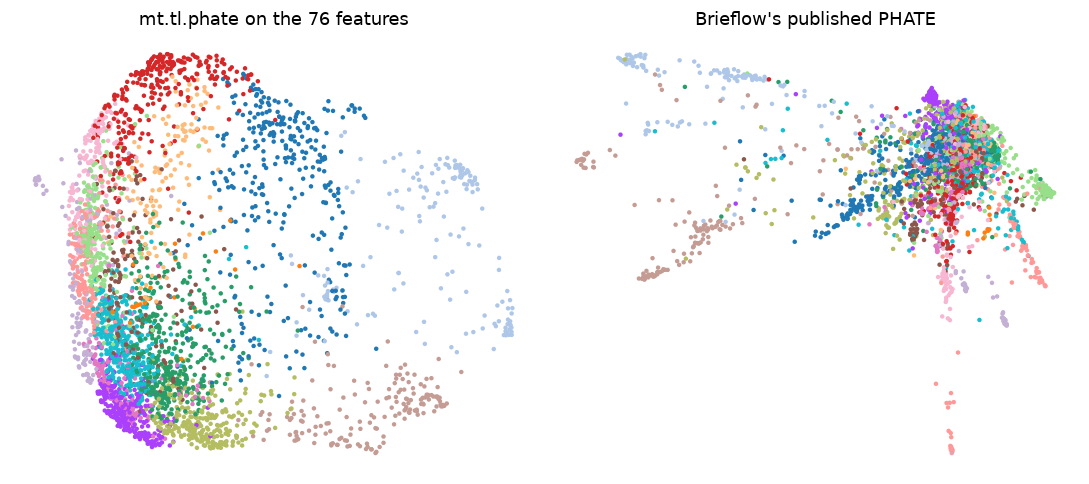

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, basis, title in [
    (axes[0], "phate", "mt.tl.phate on the 76 features"),
    (axes[1], "brieflow_phate", "Brieflow's published PHATE"),
]:
    sc.pl.embedding(genes, basis=basis, color="leiden_phate", ax=ax, show=False, title=title, frameon=False)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
fig.tight_layout()
plt.show()

## Clusters against known biology

Each clustering is scored by how much more often two genes that share a set land in the same cluster than any two
genes do. The sets are CORUM complexes, the CORUM complexes of at most 20 genes, so that a few large complexes such as
the ribosome don't supply most of the pairs, and the Reactome pathways of at most 100 genes.

In [4]:
reference = {
    "CORUM": (mt.ds.corum(), None),
    "CORUM, complexes of at most 20 genes": (mt.ds.corum(), 20),
    "Reactome, pathways of at most 100 genes": (mt.ds.gene_sets("Reactome"), 100),
}


def member_pairs(net, max_size):
    """Every pair of screened genes that share a set, counted once."""
    present = set(genes.obs_names)
    pairs = set()
    for _, grp in net.groupby("source"):
        members = sorted(set(grp["target"].astype(str)) & present)
        if max_size is None or len(members) <= max_size:
            pairs |= {(a, b) for i, a in enumerate(members) for b in members[i + 1 :]}
    return tuple(np.array(side) for side in zip(*pairs, strict=True))


pairs = {name: member_pairs(*spec) for name, spec in reference.items()}


def enrichment(labels, left, right):
    """How much more often members of a set share a cluster than any two genes do."""
    labels = pd.Series(np.asarray(labels).astype(str), index=genes.obs_names)
    sizes = labels.value_counts().to_numpy().astype(float)
    chance = (sizes * (sizes - 1)).sum() / (len(labels) * (len(labels) - 1))
    return (labels.loc[left].to_numpy() == labels.loc[right].to_numpy()).mean() / chance


pd.DataFrame({name: [len(left)] for name, (left, right) in pairs.items()}, index=["pairs among the hit genes"])

,CORUM,"CORUM, complexes of at most 20 genes","Reactome, pathways of at most 100 genes"
pairs among the hit genes,22327,5610,141609


The score rises with the number of clusters, so the graphs are compared at matched cluster counts. Each graph is
clustered at a range of resolutions with five seeds, which move PHATE's landmarks and Leiden's starting partition, and
the score is interpolated at 25, 50 and 100 clusters and at 213, the number of Brieflow's 227 clusters that hold one
of these genes. Brieflow's clusters are scored once, because only its published labels are available. Beside the
PHATE graph and a cosine kNN graph with the same ten neighbours on the 76 features, the same two graphs are built on
50 principal components of the features.

In [5]:
sc.pp.pca(genes, n_comps=50, random_state=SEED)
SEEDS = range(5)
RESOLUTIONS = [0.5, 1, 2, 4, 8, 16, 24, 32, 48, 64]


def graphs(seed):
    """The four graphs, built from one seed; only the PHATE landmarks depend on it."""
    adata = genes.copy()
    mt.tl.phate(adata, use_rep=None, knn=10, metric="cosine", seed=seed, key_added="phate_features")
    mt.tl.phate(adata, use_rep="X_pca", knn=10, metric="cosine", seed=seed, key_added="phate_pcs")
    sc.pp.neighbors(adata, use_rep="X", n_neighbors=10, metric="cosine", key_added="knn_features")
    sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=10, metric="cosine", key_added="knn_pcs")
    return adata


rows = []
for seed in SEEDS:
    adata = graphs(seed)
    for graph in ["phate_features", "knn_features", "phate_pcs", "knn_pcs"]:
        for resolution in RESOLUTIONS:
            sc.tl.leiden(
                adata,
                resolution=resolution,
                obsp=f"{graph}_connectivities",
                key_added="sweep",
                flavor="igraph",
                n_iterations=2,
                directed=False,
                random_state=seed,
            )
            for name, (left, right) in pairs.items():
                rows.append(
                    {
                        "graph": graph,
                        "seed": seed,
                        "resolution": resolution,
                        "reference": name,
                        "clusters": adata.obs["sweep"].nunique(),
                        "enrichment": enrichment(adata.obs["sweep"], left, right),
                    }
                )
sweep = pd.DataFrame(rows)
n_brieflow = genes.obs["brieflow_cluster"].nunique()
brieflow = pd.Series(
    {name: enrichment(genes.obs["brieflow_cluster"], left, right) for name, (left, right) in pairs.items()}
)
print(f"Brieflow's clusters holding a hit gene: {n_brieflow}")

Brieflow's clusters holding a hit gene: 213


In [6]:
MATCHED = [25, 50, 100, n_brieflow]


def at_matched(grp):
    """Enrichment interpolated, on a log scale of cluster counts, at each matched count."""
    grp = grp.groupby("clusters")["enrichment"].mean().sort_index()
    return pd.Series(np.interp(np.log(MATCHED), np.log(grp.index.to_numpy(float)), grp.to_numpy()), index=MATCHED)


matched = sweep.groupby(["reference", "graph", "seed"]).apply(at_matched)
summary = matched.groupby(["reference", "graph"]).agg(["mean", "std"])
table = (
    summary.xs("mean", axis=1, level=1).round(1).astype(str)
    + " ± "
    + summary.xs("std", axis=1, level=1).round(1).astype(str)
)
table.columns = [f"{k} clusters" for k in MATCHED]
table["Brieflow, its own clusters"] = [
    f"{brieflow[ref]:.1f}" if graph == "phate_features" else "" for ref, graph in table.index
]
assert sweep["clusters"].max() >= n_brieflow and sweep["clusters"].min() <= MATCHED[0]
table

25 clusters  \
reference                               graph                        
CORUM                                   knn_features     4.2 ± 0.1   
                                        knn_pcs          3.8 ± 0.2   
                                        phate_features   4.0 ± 0.1   
                                        phate_pcs        4.0 ± 0.2   
CORUM, complexes of at most 20 genes    knn_features     5.1 ± 0.0   
                                        knn_pcs          4.4 ± 0.2   
                                        phate_features   5.0 ± 0.2   
                                        phate_pcs        4.6 ± 0.2   
Reactome, pathways of at most 100 genes knn_features     1.8 ± 0.0   
                                        knn_pcs          1.7 ± 0.1   
                                        phate_features   1.8 ± 0.1   
                                        phate_pcs        1.7 ± 0.1   

                                                       50 clusters  \
reference                               graph                        
CORUM                                   knn_features     6.4 ± 0.1   
                                        knn_pcs          6.3 ± 0.1   
                                        phate_features   6.7 ± 0.2   
                                        phate_pcs        6.6 ± 0.2   
CORUM, complexes of at most 20 genes    knn_features     8.5 ± 0.1   
                                        knn_pcs          7.7 ± 0.2   
                                        phate_features   8.6 ± 0.1   
                                        phate_pcs        8.0 ± 0.1   
Reactome, pathways of at most 100 genes knn_features     2.4 ± 0.0   
                                        knn_pcs          2.2 ± 0.0   
                                        phate_features   2.5 ± 0.1   
                                        phate_pcs        2.3 ± 0.0   

                                                       100 clusters  \
reference                               graph                         
CORUM                                   knn_features     10.4 ± 0.1   
                                        knn_pcs          11.2 ± 0.1   
                                        phate_features   10.4 ± 0.2   
                                        phate_pcs        11.5 ± 0.4   
CORUM, complexes of at most 20 genes    knn_features     14.0 ± 0.5   
                                        knn_pcs          13.4 ± 0.3   
                                        phate_features   14.6 ± 0.4   
                                        phate_pcs        14.0 ± 0.1   
Reactome, pathways of at most 100 genes knn_features      3.2 ± 0.1   
                                        knn_pcs           3.1 ± 0.1   
                                        phate_features    3.3 ± 0.1   
                                        phate_pcs         3.2 ± 0.0   

                                                       213 clusters  \
reference                               graph                         
CORUM                                   knn_features     15.9 ± 0.9   
                                        knn_pcs          17.9 ± 0.7   
                                        phate_features   16.5 ± 0.2   
                                        phate_pcs        18.4 ± 1.4   
CORUM, complexes of at most 20 genes    knn_features     27.8 ± 0.2   
                                        knn_pcs          25.3 ± 0.5   
                                        phate_features   27.6 ± 0.3   
                                        phate_pcs        25.9 ± 0.7   
Reactome, pathways of at most 100 genes knn_features      4.4 ± 0.2   
                                        knn_pcs           4.4 ± 0.1   
                                        phate_features    4.6 ± 0.1   
                                        phate_pcs         4.6 ± 0.2   

                                                       Brieflow, its own clusters  
reference          

The table gives the mean and standard deviation over the five seeds. The PHATE graph and the cosine kNN graph built
from the same input score within 0.6 of each other at every matched count and against every reference, so on this
screen Leiden on the PHATE graph is equivalent to Leiden on a cosine kNN graph with the same neighbours. The
differences are at most 0.6 either way, which is small next to the effect of the input below.

The input changes the scores more than the graph does, and it changes them in both directions. On the 76 features,
each graph keeps small complexes together more often than the same graph on the principal components, e.g. 27.6 for
the PHATE graph at 213 clusters against 25.9. On the principal components, each graph scores higher on all of CORUM
from 100 clusters on, e.g. 18.4 for the PHATE graph at 213 clusters against 16.5, and on Reactome the features are
ahead by 0.2 or less.

Brieflow's own clusters score in the same range. At 213 clusters they score 17.4 on CORUM, 25.5 on small complexes and
4.8 on Reactome, against 16.5, 27.6 and 4.6 for Leiden on the PHATE graph of the features.

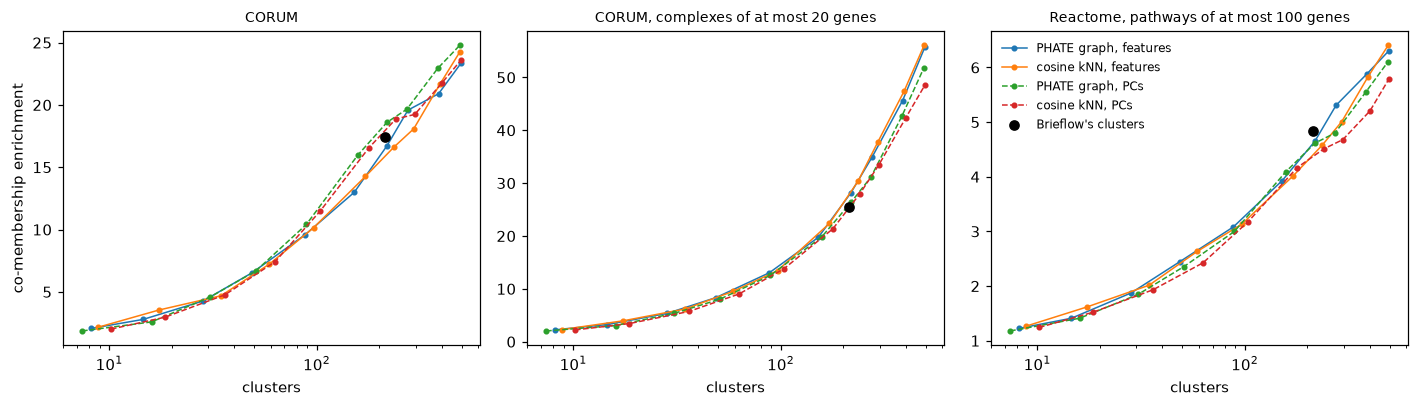

In [7]:
labels = {
    "phate_features": "PHATE graph, features",
    "knn_features": "cosine kNN, features",
    "phate_pcs": "PHATE graph, PCs",
    "knn_pcs": "cosine kNN, PCs",
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, grp) in zip(axes, sweep.groupby("reference", sort=False), strict=True):
    for graph, label in labels.items():
        g = grp[grp["graph"] == graph].groupby("resolution")[["clusters", "enrichment"]].mean()
        ax.plot(g["clusters"], g["enrichment"], marker=".", lw=1, label=label, ls="-" if "features" in graph else "--")
    ax.scatter([n_brieflow], [brieflow[name]], color="black", zorder=3, label="Brieflow's clusters")
    ax.set_xscale("log")
    ax.set_xlabel("clusters")
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("co-membership enrichment")
axes[-1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## The potential as a representation

The diffusion potential holds each gene's `-log` transition probabilities after `t` steps of the walk, and its
columns share a large offset. Centre the potential on its column means before any similarity metric, so that the
similarity compares how the genes differ rather than the offset they share. {func}`~mantispy.metrics.known_relationships`
then asks what share of CORUM pairs fall in the tails of the similarity distribution, against a null that shuffles the
annotation.

In [8]:
potential = genes.obsm["X_phate_potential"].astype(np.float64)
genes.obsm["potential_centred"] = potential - potential.mean(axis=0)
genes.obsm["potential_raw"] = potential
genes.obs["Metadata_Gene"] = genes.obs_names
corum = mt.ds.corum()
recall = pd.concat(
    [
        mt.metrics.known_relationships(
            genes, corum, label_key="Metadata_Gene", use_rep=rep, n_permutations=100, seed=SEED
        ).assign(representation=name)
        for rep, name in [
            (None, "the 76 features"),
            ("potential_centred", "potential, centred"),
            ("potential_raw", "potential, not centred"),
        ]
    ]
)
recall.set_index("representation")[["value", "null", "pvalue"]].round(3)

,value,null,pvalue
representation,,,
the 76 features,0.299,0.123,0.01
"potential, centred",0.209,0.111,0.01
"potential, not centred",0.178,0.087,0.01


Centring raises the potential's recall from 0.178 to 0.209, although its null rises with it, from 0.087 to 0.111.
The 76 features keep almost twice the margin over their null, 0.299 against 0.123, so to retrieve complexes from
pairwise similarity, use the features rather than the potential.

## What to take away

- `mt.tl.phate(genes, use_rep=None, knn=10, metric="cosine")` and
  `mt.tl.cluster(genes, method="leiden", neighbors_key="phate")` run Brieflow's PHATE and Leiden step, and the clusters
  score in the same range as Brieflow's published ones, although the embedding's layout differs from Brieflow's.
- On this screen Leiden on the PHATE graph scores the same as Leiden on a cosine kNN graph with the same neighbours,
  so use the PHATE graph for parity with Brieflow and for the picture, since it doesn't give better clusters.
- The input matters more than the graph. The 76 features keep small complexes together more often, and principal
  components keep more of all CORUM together at fine resolution.
- Centre the potential before measuring similarity on it, and prefer the features for retrieving complexes.